# wellfit: optimizer example (line broadening)

The data and model are the same as in `grid_example.ipynb`: four lines A-D, v sin i = 100 km/s and v_macro = 10 km/s,
correlated noise, errors quoted too small, and line D made with v sin i = 140 km/s. Here the two parameters are
continuous and fitted with a minimizer instead of a grid.

wellfit needs two things from you:

- `residuals(theta)`: model − data on the fitted pixels;
- `minimize(objective, theta_start)`: any minimizer that returns the best theta.

Every grid operation becomes a refit:

- the fit and `sigma_sys` are alternated until both are stable;
- stat errors come from the curvature of chi2_eff, or from a profile scan;
- each line left out, and each bootstrap replicate over lines, is a refit.

In [1]:
import sys
sys.path.insert(0, '..')   # or install the package: pip install -e ..
import numpy as np
import matplotlib.pyplot as plt
import wellfit as wf
import toy_lines as tl     # toy broadening model + synthetic data for these examples
%matplotlib inline
from scipy.optimize import minimize

## 1. Data

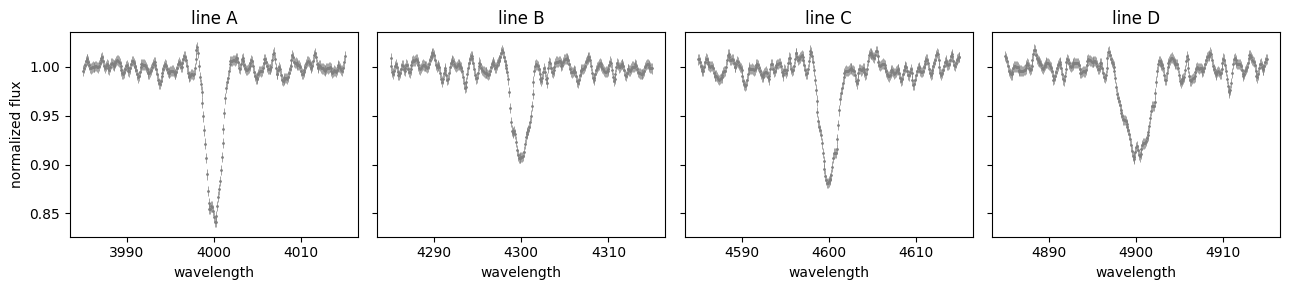

In [2]:
TRUTH = dict(vsini=100., vmacro=10., vsini_D=140., snr=150.)
d = tl.make_data(**TRUTH)
lam, flux, err_quoted, groups, names = d['lam'], d['flux'], d['err'], d['groups'], d['names']

fig, axs = plt.subplots(1, 4, figsize=(13, 3), sharey=True)
for j, ax in enumerate(axs):
    m = groups == j
    ax.errorbar(lam[m], flux[m], err_quoted[m], fmt='.', ms=2, color='0.5', lw=0.5)
    ax.set_title(f'line {names[j]}'); ax.set_xlabel('wavelength')
axs[0].set_ylabel('normalized flux'); plt.tight_layout()

## 2. Noise: rescale the errors and measure the pixel correlation

Both come from the line-free continuum on either side of each line (`d['ref_ranges']`). A constant baseline (`deg=0`) is
fitted in each range because the data are already normalized.

- `measure_error_scale` multiplies the quoted errors so the continuum scatter has unit width. The data were made with
  errors quoted 0.8x too small, so expect a factor of about 1.25.
- `measure_n_corr` measures how many neighbouring pixels share one independent piece of information. The noise was
  smoothed over about 1.5 pixels, so expect n_corr ≈ 5. Short continuum segments bias the estimate slightly low.

In [3]:
err, factor = wf.measure_error_scale(lam, flux, err_quoted, d['ref_ranges'], deg=0)
n_corr, rho = wf.measure_n_corr(lam, flux, err, d['ref_ranges'], deg=0)
print(f"error scale factor = {factor:.2f}   (injected 1 / 0.8 = 1.25)")
print(f"n_corr = {n_corr:.2f}   (injected {d['truth']['n_corr']:.2f}); rho_1..4 = {np.round(rho[:4], 2)}")
print(f"{lam.size} pixels -> {lam.size / n_corr:.0f} independent pixels")

error scale factor = 1.26   (injected 1 / 0.8 = 1.25)
n_corr = 4.94   (injected 5.32); rho_1..4 = [0.88 0.62 0.34 0.13]
1204 pixels -> 244 independent pixels


## 3. Model and minimizer

v sin i and v_macro cannot be negative, so the minimizer is bounded. The model has to be a smooth function of the
parameters for the finite-difference curvature to make sense. `toy_lines` applies its kernels through their analytic
Fourier transforms for that reason.

In [4]:
def residuals(theta, m=slice(None)):
    vsini, vmacro = theta
    return tl.model(lam[m], groups[m], vsini, vmacro) - flux[m]

def nelder_mead(objective, theta_start):
    # bounds sized from theta_start: the profile scans call this with the scanned parameter removed
    return minimize(objective, theta_start, method='Nelder-Mead', bounds=[(0, 400)] * len(theta_start),
                    options={'xatol': 1e-3, 'fatol': 1e-6}).x

theta0 = [50., 30.]

## 4. Naive fit vs wellfit

The naive fit uses the quoted errors, `n_corr = 1` and no systematic floor. For wellfit we also ask for profile scans:
at each value of one parameter the other is refitted, and the errors are read where Δchi2_eff = 1. Unlike the
curvature, these errors are asymmetric and correct next to a bound such as v_macro = 0.

In [5]:
naive = wf.fit_optimizer(residuals, nelder_mead, theta0, err_quoted, n_corr=1., fit_sigma_sys=False,
                         param_names=['vsini', 'vmacro'])
fit = wf.fit_optimizer(residuals, nelder_mead, theta0, err, n_corr, groups=groups, group_names=names,
                       param_names=['vsini', 'vmacro'], n_boot=100,
                       profile={'vsini': np.arange(60, 160.1, 1.), 'vmacro': np.arange(0, 60.1, 1.)})

print(f"naive: chi2 = {naive.chi2:.0f} for {naive.nu:.0f} dof (reduced chi2 = {naive.chi2 / naive.nu:.1f})")
for k, (v, ep, em, _, _) in naive.results.items():
    print(f"  {k:7s} = {v:6.1f} +{ep:.1f} -{em:.1f}")
print()
print(fit.summary())
print("\ncurvature (Hessian) errors for comparison:", dict(zip(fit.param_names, np.sqrt(np.diag(fit.cov)).round(1))))

naive: chi2 = 2886 for 1202 dof (reduced chi2 = 2.4)
  vsini   =  106.0 +1.1 -1.1
  vmacro  =   22.6 +1.5 -1.5

n_data = 1204, n_corr = 4.94 -> 243.8 independent points, nu = 241.8
sigma_sys = 0.004857; best fit: chi2 = 1818.0 (raw), chi2_eff = 241.8
Parameters (value +stat -stat, +sys -sys):
  vsini             106  +3.524 -4.268   sys +10.34 -5.175
  vmacro          22.62  +5.439 -5.359   sys +6.127 -9.229
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            41.5 /   60.9  tension    5.5  109.3  28.27
  B                0            43.6 /   60.9  tension    0.5  105.2  25.84
  C                0            57.2 /   60.9  tension    2.5  109.9  23.36
  D                0            99.5 /   60.9  tension   19.5  100.8  12.23

curvature (Hessian) errors for comparison: {'vsini': 3.8, 'vmacro': 5.3}


## 5. Profiles

The profiled chi2_eff of each parameter. The dotted line marks Δchi2_eff = 1 (68% for one parameter) and the dashed
parabola is the curvature approximation. Where they differ, use the profile.

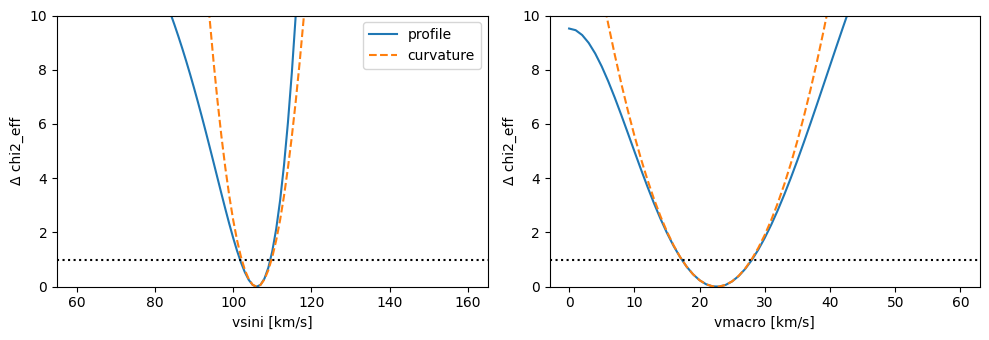

In [6]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, (k, (vals, prof)) in zip(axs, fit.profiles.items()):
    i = fit.param_names.index(k)
    ax.plot(vals, prof - fit.chi2_eff, 'C0', label='profile')
    ax.plot(vals, (vals - fit.theta[i])**2 / fit.cov[i, i], 'C1--', label='curvature')
    ax.axhline(1, color='k', ls=':')
    ax.set_ylim(0, 10); ax.set_xlabel(f'{k} [km/s]'); ax.set_ylabel('Δ chi2_eff')
axs[0].legend(); plt.tight_layout()

## 5b. The 2D posterior

The optimizer gives a best fit and a covariance, not a posterior map. With only two parameters we can evaluate
chi2_eff on a mesh around the best fit to show the real posterior exp(−chi2_eff/2). This is a few thousand model
evaluations, used for display only.

- **Shading and solid contours:** the exact posterior, with Δchi2_eff = 2.30 and 6.18 (68% and 95% for two
  parameters jointly).
- **Dashed ellipses:** the same levels from the curvature covariance `fit.cov`. Where they match the solid contours,
  the curvature errors can be trusted.
- **Points:** the best fit in each bootstrap replicate over lines (`fit.theta_boot`). Their spread is the systematic
  error, on the same axes.

With more than about three parameters a mesh is no longer feasible. Sample `wf.log_likelihood(residuals(theta), err,
n_corr, fit.sigma_sys)` with an MCMC sampler such as emcee and make a corner plot instead.

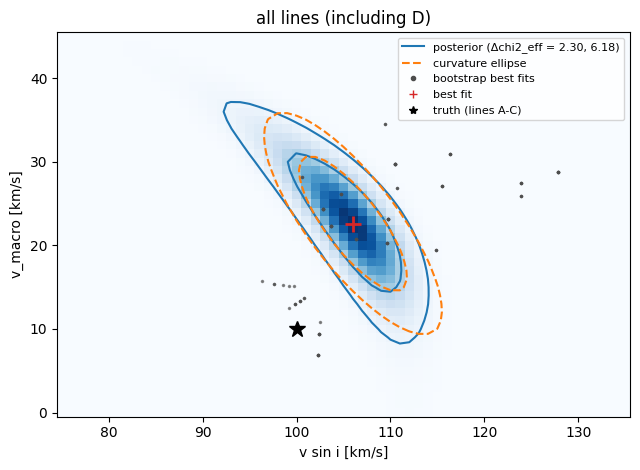

In [7]:
vs_mesh, vm_mesh = np.linspace(75, 135, 61), np.linspace(0, 45, 46)
c2 = np.array([[wf.chi2_eff(residuals([a, b]), err, n_corr, fit.sigma_sys) for b in vm_mesh] for a in vs_mesh])
d2 = (c2 - min(c2.min(), fit.chi2_eff)).T                       # Delta chi2_eff, (vmacro, vsini)

A, B = np.meshgrid(vs_mesh, vm_mesh)
dx = np.stack([A - fit.theta[0], B - fit.theta[1]], axis=-1)
d2_curv = np.einsum('...i,ij,...j->...', dx, np.linalg.inv(fit.cov), dx)   # Gaussian approximation

fig, ax = plt.subplots(figsize=(6.5, 4.8))
ax.pcolormesh(vs_mesh, vm_mesh, np.exp(-0.5 * d2), cmap='Blues', shading='auto')
ax.contour(vs_mesh, vm_mesh, d2, levels=[2.30, 6.18], colors='C0', linestyles='-')
ax.contour(vs_mesh, vm_mesh, d2_curv, levels=[2.30, 6.18], colors='C1', linestyles='--')
ax.plot(*fit.theta_boot.T, '.', color='0.3', ms=3, alpha=0.6)
ax.plot(*fit.theta, 'C3+', ms=12, mew=2)
ax.plot(TRUTH['vsini'], TRUTH['vmacro'], 'k*', ms=12)
for lab, kw in [('posterior (Δchi2_eff = 2.30, 6.18)', dict(color='C0')), ('curvature ellipse', dict(color='C1', ls='--')),
                ('bootstrap best fits', dict(color='0.3', marker='.', ls='')), ('best fit', dict(color='C3', marker='+', ls='')),
                ('truth (lines A-C)', dict(color='k', marker='*', ls=''))]:
    ax.plot([], [], label=lab, **kw)
ax.set_xlabel('v sin i [km/s]'); ax.set_ylabel('v_macro [km/s]'); ax.legend(fontsize=8, loc='upper right')
ax.set_title('all lines (including D)'); plt.tight_layout()

Line D is still in this fit, so the posterior sits away from the truth.

- **Ellipse vs exact contours:** the curvature ellipse captures the core and the tilt, i.e. the v sin i–v_macro trade-off.
  It misses the extended tail toward low v sin i and high v_macro, which is why the profile errors in section 5 are
  asymmetric.
- **Bootstrap points:** with only four lines there are few distinct resamplings, so the points cluster. Replicates that
  happen to leave out line D land near the truth, and those that count it twice land far away. This spread, well
  beyond the stat contours, is why the sys errors exceed the stat errors here. The lines disagree with each other more
  than the noise allows, and section 6 finds the line responsible.

## 6. Line diagnostics: tension

As with the grid, line D has a large tension. Leave it out by giving `residuals` only the pixels of lines A-C, and
refit.

Optimizers can get stuck where v sin i and v_macro trade off against each other, or against a bound. The
leave-one-out and bootstrap refits start from the best fit. If the results look odd, run `fit_optimizer` from a few
starting points (`theta0`) or check with the grid stream.

n_data = 903, n_corr = 4.94 -> 182.8 independent points, nu = 180.8
sigma_sys = 0.001232; best fit: chi2 = 923.1 (raw), chi2_eff = 180.8
Parameters (value +stat -stat, +sys -sys):
  vsini           100.8  +2.299 -2.561   sys +3.097 -2.85
  vmacro          12.23  +4.783 -5.881   sys +3.068 -5.087
Groups (chi2_eff / expected, tension, leave-one-out best vsini, vmacro):
  A                0            48.1 /   60.9  tension    0.4  102.3  6.9
  B                0            60.9 /   60.9  tension    0.7  98.54  15.2
  C                0            71.8 /   60.9  tension    0.4  102.5  10.89


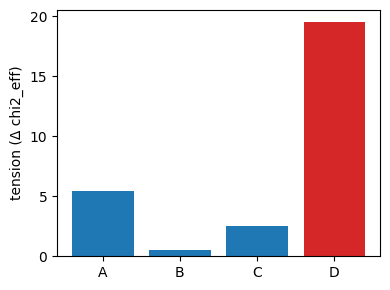

In [8]:
fig, ax = plt.subplots(figsize=(4, 3))
ax.bar(names, fit.tension, color=['C0'] * 3 + ['C3'])
ax.set_ylabel('tension (Δ chi2_eff)'); plt.tight_layout()

keep = groups != names.index('D')
fit_noD = wf.fit_optimizer(lambda th: residuals(th, keep), nelder_mead, fit.theta, err[keep], n_corr,
                           groups=groups[keep], group_names=names[:3], param_names=['vsini', 'vmacro'], n_boot=100,
                           profile={'vsini': np.arange(60, 160.1, 1.), 'vmacro': np.arange(0, 60.1, 1.)})
print(fit_noD.summary())

## MCMC instead?

To sample instead, use `wf.log_likelihood(residuals(theta), err, n_corr, sigma_sys)` as the likelihood. It is
−chi2_eff/2, so the posterior widths account for the correlated pixels. Fix `sigma_sys` from `fit.sigma_sys`, or sample
it as a free parameter.